# Luminosity functions

`phi(M)`, the number of galaxies per unit volume per magnitude, in (Mpc/h)^-3 mag^-1, with absolute magnitudes `M - 5 log10 h`.

GALFORM stores a luminosity for every galaxy in every band of its run. These are intrinsic, with no dust, so blue and UV luminosity functions come out brighter than observed ones. See `examples/dust/dust_attenuation.ipynb` to add dust.

Magnitudes are AB by default. Use `system='Vega'` to compare with Vega-based surveys such as 2MASS (K) or 2dFGRS (bJ).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import oh_mpl_paper

import galform_analysis
from galform_analysis import set_base_dir, get_base_dir, SimulationConfig, load_redshift_mapping

oh_mpl_paper.setconfig("k.wang")

# Configure the path to your GALFORM output directory once per session:
# set_base_dir('/cosma5/data/durham/<user>/Galform_Out/L800/model')
BASE_DIR = str(get_base_dir())
SIM = 'L800'

## Which bands are available?

Each run has its own list of bands. Choose one by its `label`, which is case-sensitive (`R` is Cousins R and `SDSS-r` is SDSS r), and by `frame`, which is `'rest'` or `'observer'`. You can also give its number from the `index` column.

In [2]:
import os
import polars as pl
from galform_analysis import list_bands

bands = list_bands(os.path.join(BASE_DIR, 'iz271'), ivol=0)
with pl.Config(tbl_rows=30, fmt_str_lengths=40):
    print(bands.filter(pl.col('frame') == 'rest').drop('name').head(21))

shape: (21, 5)
┌───────┬────────────┬───────┬──────────────┬───────────┐
│ index ┆ label      ┆ frame ┆ lambda_eff   ┆ a0_ab     │
│ ---   ┆ ---        ┆ ---   ┆ ---          ┆ ---       │
│ i64   ┆ str        ┆ str   ┆ f64          ┆ f64       │
╞═══════╪════════════╪═══════╪══════════════╪═══════════╡
│ 1     ┆ TH1500     ┆ rest  ┆ 1489.973511  ┆ -2.500105 │
│ 2     ┆ TH2800     ┆ rest  ┆ 2790.460938  ┆ -1.545521 │
│ 3     ┆ U          ┆ rest  ┆ 3506.894775  ┆ -0.903132 │
│ 4     ┆ B          ┆ rest  ┆ 4369.145508  ┆ 0.116632  │
│ 5     ┆ V          ┆ rest  ┆ 5403.780273  ┆ 0.007931  │
│ 6     ┆ R          ┆ rest  ┆ 6655.717285  ┆ -0.225865 │
│ 7     ┆ I          ┆ rest  ┆ 8101.680664  ┆ -0.429968 │
│ 8     ┆ UKIRT-J    ┆ rest  ┆ 12296.887695 ┆ -0.884722 │
│ 9     ┆ UKIRT-H    ┆ rest  ┆ 16532.851562 ┆ -1.386303 │
│ 10    ┆ UKIRT-K    ┆ rest  ┆ 21967.658203 ┆ -1.86988  │
│ 11    ┆ Bj         ┆ rest  ┆ 4481.508301  ┆ 0.088781  │
│ 12    ┆ SDSS-u     ┆ rest  ┆ 3551.298096  ┆ -0.910451 │

## Single subvolume, single snapshot

In [3]:
from galform_analysis.analysis.luminosity_functions import (
    lf_given_redshift_and_subvolume,
    avg_lf_given_redshift_and_subvolumes,
    avg_lf_given_redshifts_and_subvolume,
    lfs_given_redshifts_and_subvolume,
    schechter_magnitude,
)
from galform_analysis.config import DEFAULT_MAGNITUDE_BINS, get_snapshot_redshift

iz_path = os.path.join(BASE_DIR, 'iz271')
res = lf_given_redshift_and_subvolume(iz_path, ivol=0, band='SDSS-r')
print(f"z={res['z']:.4f},  V_ivol={res['V_ivol']:.1f} (Mpc/h)^3,  "
      f"band={res['band']} (index {res['band_index']}, {res['frame']} "
      f"frame, {res['system']}),  N in bins={res['counts'].sum()}")

z=0.0000,  V_ivol=155626.1 (Mpc/h)^3,  band=SDSS-r (index 14, rest frame, AB),  N in bins=39671


## Average over subvolumes: K band vs 2MASS

K-band dust attenuation is small, so the intrinsic model can be compared directly with the Cole et al. (2001) Schechter fit (Vega: `M* - 5 log h = -23.44`, `alpha = -0.96`, `phi* = 0.0108 h^3 Mpc^-3`). `phi_std` is the scatter between subvolumes.

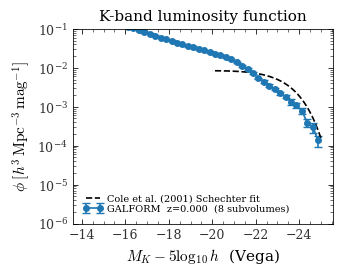

In [4]:
IZ_NUM = 271
IVOLS  = list(range(8))   # use more subvolumes for better statistics

z = get_snapshot_redshift(f'iz{IZ_NUM}', SIM)
res = avg_lf_given_redshift_and_subvolumes(IZ_NUM, IVOLS, 'UKIRT-K',
                                           system='Vega', base_dir=BASE_DIR)

fig, ax = plt.subplots()
ok = res['phi'] > 0
ax.errorbar(res['centers'][ok], res['phi'][ok], yerr=res['phi_std'][ok],
            fmt='o-', ms=4, capsize=3, label=f'GALFORM  z={z:.3f}  ({res["n_used"]} subvolumes)')
M = np.linspace(-25, -20, 200)   # magnitude range of the 2MASS fit
ax.plot(M, schechter_magnitude(M, phi_star=0.0108, M_star=-23.44, alpha=-0.96),
        'k--', label='Cole et al. (2001) Schechter fit')
ax.set_yscale('log')
ax.set_ylim(1e-6, 1e-1)
ax.invert_xaxis()   # bright galaxies on the right
ax.set_xlabel(r'$M_K - 5\log_{10}h$  (Vega)')
ax.set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
ax.set_title('K-band luminosity function')
ax.legend()
plt.show()

## Several bands at z = 0

The SDSS bands from u to z, shaded from dark to light in order of wavelength.

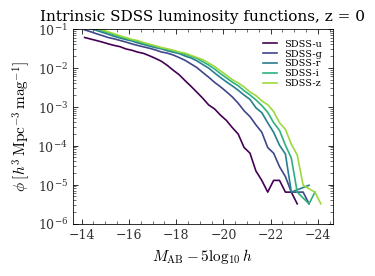

In [5]:
SDSS = ['SDSS-u', 'SDSS-g', 'SDSS-r', 'SDSS-i', 'SDSS-z']
colours = plt.cm.viridis(np.linspace(0.0, 0.85, len(SDSS)))

fig, ax = plt.subplots()
for band, colour in zip(SDSS, colours):
    r = avg_lf_given_redshift_and_subvolumes(271, IVOLS, band, base_dir=BASE_DIR)
    ok = r['phi'] > 0   # empty bins cannot be drawn on a log axis
    ax.plot(r['centers'][ok], r['phi'][ok], color=colour, label=band)
ax.set_yscale('log')
ax.set_ylim(1e-6, 1e-1)
ax.invert_xaxis()
ax.set_xlabel(r'$M_{\rm AB} - 5\log_{10}h$')
ax.set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
ax.set_title('Intrinsic SDSS luminosity functions, z = 0')
ax.legend()
plt.show()

## Rest frame vs observer frame

At z > 0 the observer-frame band samples bluer rest-frame light. The two frames are identical at z = 0.

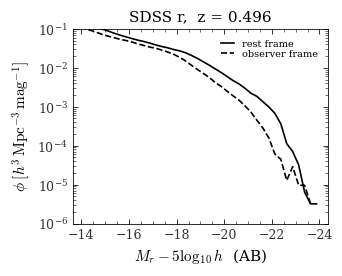

In [6]:
fig, ax = plt.subplots()
for frame, style in (('rest', '-'), ('observer', '--')):
    r = avg_lf_given_redshift_and_subvolumes(207, IVOLS, 'SDSS-r', frame=frame,
                                             base_dir=BASE_DIR)
    ok = r['phi'] > 0   # empty bins cannot be drawn on a log axis
    ax.plot(r['centers'][ok], r['phi'][ok], 'k' + style, label=f'{frame} frame')
ax.set_yscale('log')
ax.set_ylim(1e-6, 1e-1)
ax.invert_xaxis()
ax.set_xlabel(r'$M_r - 5\log_{10}h$  (AB)')
ax.set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
ax.set_title(f"SDSS r,  z = {r['z']:.3f}")
ax.legend()
plt.show()

## Disk and bulge components

`component='disk'` or `'bulge'` uses one component's light only.

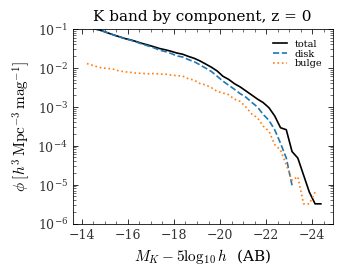

In [7]:
fig, ax = plt.subplots()
for component, style in (('total', 'k-'), ('disk', 'C0--'), ('bulge', 'C1:')):
    r = avg_lf_given_redshift_and_subvolumes(271, IVOLS, 'UKIRT-K',
                                             component=component, base_dir=BASE_DIR)
    ok = r['phi'] > 0   # empty bins cannot be drawn on a log axis
    ax.plot(r['centers'][ok], r['phi'][ok], style, label=component)
ax.set_yscale('log')
ax.set_ylim(1e-6, 1e-1)
ax.invert_xaxis()
ax.set_xlabel(r'$M_K - 5\log_{10}h$  (AB)')
ax.set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
ax.set_title('K band by component, z = 0')
ax.legend()
plt.show()

## Redshift evolution (one subvolume across multiple snapshots)

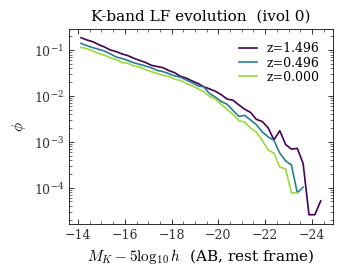

In [8]:
IZ_NUMS = [155, 207, 271]   # adjust to snapshots available in your run
IVOL    = 0

df = lfs_given_redshifts_and_subvolume(IVOL, IZ_NUMS, 'UKIRT-K', base_dir=BASE_DIR)
if df is None:
    print("No data — check IZ_NUMS match your simulation outputs.")
else:
    groups = list(df.group_by('z', maintain_order=True))
    colours = plt.cm.viridis(np.linspace(0.0, 0.85, len(groups)))
    fig, ax = plt.subplots()
    for ((z_val,), grp), colour in zip(groups, colours):
        ok = grp['phi'] > 0
        ax.plot(grp['mag'].filter(ok), grp['phi'].filter(ok), color=colour,
                label=f'z={z_val:.3f}')
    ax.set_yscale('log')
    ax.invert_xaxis()
    ax.set_xlabel(r'$M_K - 5\log_{10}h$  (AB, rest frame)')
    ax.set_ylabel(r'$\phi$')
    ax.set_title('K-band LF evolution  (ivol 0)')
    ax.legend(fontsize=9)
    plt.show()